<a href="https://colab.research.google.com/github/Alex20david/Practica03-Perceptron-AlexChacha/blob/main/Practica_3_Alex_Chacha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRÁCTICA DE LABORATORIO N.º 3**
## **EL PERCEPTRÓN**

**Carrera:** Ingeniería en Ciencias de la Computación  
**Asignatura:** Inteligencia Artificial  
**Estudiante:** Alex David  
**Fecha:** 13 de noviembre de 2026

### **Fase 1. Exploración del Dataset**

### 1.1 Carga del Dataset

In [9]:

X = [
    [1,7], [1,3], [3,4], [4,6], [4,2],
    [6,6], [6,2], [6,0], [7,4], [9,3],
    [9,1], [11,1], [12,3], [16,2],
    [4,8], [6,8], [8,9], [9,7], [10,11],
    [12,9], [12,6], [14,7], [16,4]
]

y = [-1]*14 + [1]*9


###Actividad 1.a — Inspección inicial

In [ ]:

print("Total de instancias:", len(X))
print("Variables de entrada:", 2)
print("Número de clases:", len(set(y)))
print("Puntos de clase -1:", y.count(-1))
print("Puntos de clase 1:", y.count(1))


Total de instancias: 23
Variables de entrada: 2
Número de clases: 2
Puntos de clase -1: 14
Puntos de clase 1: 9


**¿Qué representa cada fila de X?**
Cada fila representa un punto con dos valores, X1 y X2.

**¿Qué representa cada valor del vector y?**
Representa la clase a la que pertenece cada punto, que puede ser -1 o 1.

**¿Por qué se considera clasificación binaria?**
Porque solamente existen dos clases posibles.

### **Actividad 1.b — Separación visual de las clases:**

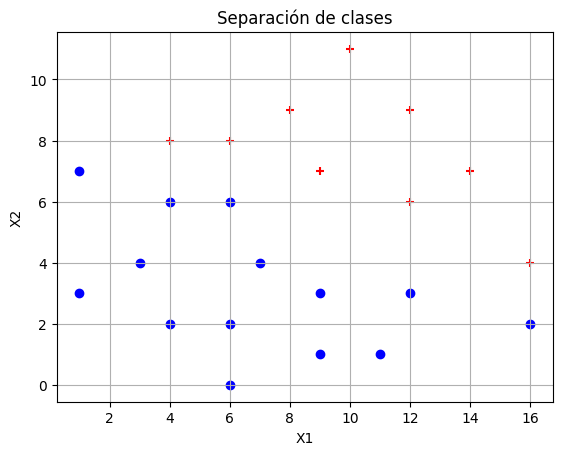

In [ ]:

import matplotlib.pyplot as plt

def graficar_puntos(X, y):
    for i in range(len(X)):
        if y[i] == -1:
            plt.scatter(X[i][0], X[i][1], color="blue", marker="o")
        else:
            plt.scatter(X[i][0], X[i][1], color="red", marker="+")

    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title("Separación de clases")
    plt.grid()
    plt.show()

graficar_puntos(X, y)


Observando únicamente la gráfica, ¿parece posible separar las dos clases mediante una sola recta? Justifica tu respuesta.

Sí, porque los puntos de las dos clases se encuentran en regiones diferentes y parece posible separarlos mediante una recta.

### Fase 2. Fundamento del Perceptrón
### Actividad 2.a — Vector de pesos

En esta actividad se inicializan tres pesos aleatorios pequeños que serán utilizados por el perceptrón.

In [1]:

import random

def initialize_weights():
    w0 = random.uniform(-0.5, 0.5)
    w1 = random.uniform(-0.5, 0.5)
    w2 = random.uniform(-0.5, 0.5)

    return [w0, w1, w2]

pesos = initialize_weights()
print("Pesos iniciales:", pesos)


Pesos iniciales: [0.1405911706680324, -0.052260995087559436, -0.05514581936512475]


**Pregunta guía: ¿Por qué el vector de pesos tiene tres valores si cada instancia de entrada solo tiene dos variables?**

Porque se necesitan dos pesos para las variables de entrada y uno adicional para el bias.

**¿Qué función cumple el bias en el modelo?**

El bias permite ajustar la posición de la frontera de decisión para separar mejor las clases.

### Actividad 2.b — Función de activación

Se implementa la función escalón bipolar, que permite al perceptrón clasificar los datos en dos clases: -1 y 1.

In [2]:

def activation(z):
    if z >= 0:
        return 1
    else:
        return -1

# Pruebas de la función
print("Para z = 5:", activation(5))
print("Para z = -3:", activation(-3))
print("Para z = 0:", activation(0))


Para z = 5: 1
Para z = -3: -1
Para z = 0: 1


**Pregunta guía: ¿Por qué en esta práctica se utilizan las etiquetas -1 y 1 en lugar de 0 y 1?**

Porque el perceptrón utiliza una función de activación bipolar que devuelve -1 o 1.

**¿Qué ventaja tiene esta representación para el algoritmo del perceptrón?**

Permite trabajar con valores positivos y negativos, facilitando la clasificación y la actualización de los pesos.

### Actividad 2.c — Cálculo de salida

Se implementa una función que calcula la suma ponderada de las entradas y utiliza la función de activación para obtener la salida del perceptrón.

In [10]:

def perceptron_compute(x, w):
    z = w[0] + w[1] * x[0] + w[2] * x[1]
    return activation(z)

print("Instancia 1:", X[0], "Salida:", perceptron_compute(X[0], pesos))
print("Instancia 2:", X[1], "Salida:", perceptron_compute(X[1], pesos))
print("Instancia 3:", X[2], "Salida:", perceptron_compute(X[2], pesos))





Instancia 1: [1, 7] Salida: -1
Instancia 2: [1, 3] Salida: -1
Instancia 3: [3, 4] Salida: -1


**Pregunta guía: ¿Cuál es la diferencia entre la suma ponderada z y la salida final del perceptrón?**

La suma ponderada z es el resultado de multiplicar las entradas por sus pesos y sumar el bias. La salida final es la clasificación obtenida al aplicar la función de activación.

**¿Por qué no basta con calcular solo z?**

Porque necesitamos convertir ese valor en una de las dos clases posibles: -1 o 1.

## Fase 3. Visualización de la Frontera de Decisión

### Actividad 3.a — Función de graficación

Se implementa una función para visualizar los puntos de ambas clases y la frontera de decisión del perceptrón, utilizando los pesos del modelo.

In [12]:

import matplotlib.pyplot as plt

def perceptron_plot(X, y, w, title):
    for i in range(len(X)):
        if y[i] == -1:
            plt.scatter(X[i][0], X[i][1], color="blue", marker="o")
        else:
            plt.scatter(X[i][0], X[i][1], color="red", marker="+")

    # Frontera de decisión
    if w[2] != 0:
        x1 = [0, 17]
        x2 = [-(w[0] + w[1] * x) / w[2] for x in x1]
        plt.plot(x1, x2, color="green", label="Frontera")
    elif w[1] != 0:
        plt.axvline(-w[0] / w[1], color="green", label="Frontera")

    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()


**Pregunta guía: ¿Qué representa geométricamente la recta generada por el perceptrón?**

La recta representa la frontera de decisión que divide el plano en dos regiones para clasificar los puntos.

**¿Qué ocurre si los pesos iniciales son aleatorios?**

La recta tendrá una posición e inclinación aleatorias, por lo que inicialmente puede no separar correctamente las clases.

### Actividad 3.b — Gráfica con pesos iniciales

Se inicializan pesos aleatorios pequeños y se grafica la frontera de decisión inicial del perceptrón para observar cómo clasifica los puntos antes del entrenamiento.

Pesos iniciales: [-0.16146976591726714, -0.15750565350735946, -0.48868463896017156]


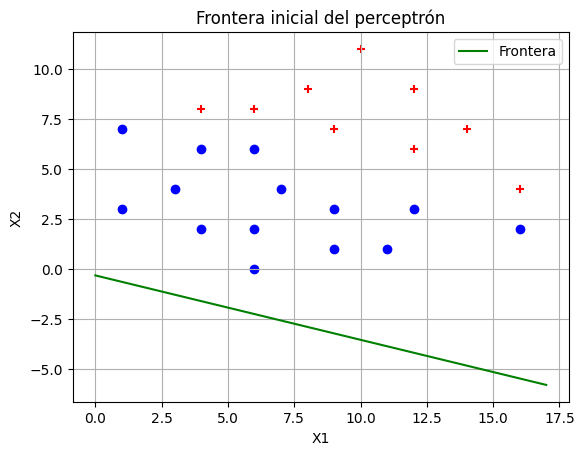

In [13]:

# Generar pesos iniciales
w_initial = initialize_weights()

# Mostrar los pesos
print("Pesos iniciales:", w_initial)

# Graficar la frontera inicial
perceptron_plot(X, y, w_initial, "Frontera inicial del perceptrón")


**Pregunta guía: ¿La frontera inicial clasifica correctamente los puntos?**

No necesariamente, ya que los pesos iniciales son aleatorios y la recta puede no separar correctamente las dos clases.

**¿Por qué no deberíamos esperar que una frontera con pesos aleatorios sea correcta?**

Porque el perceptrón todavía no ha sido entrenado y sus pesos aún no se han ajustado según los datos.

## Fase 4. Entrenamiento del Perceptrón

### Actividad 4.a — Implementación de la función de aprendizaje

Se implementa una función que permite entrenar al perceptrón mediante la actualización de sus pesos cuando se producen errores de clasificación.

In [14]:

def perceptron_learning(X, y, w, lr, max_epochs):
    w = w.copy()
    W_values = []
    E_values = []
    updates = 0

    for epoch in range(max_epochs):
        errores = 0

        for i in range(len(X)):
            prediccion = perceptron_compute(X[i], w)

            if prediccion != y[i]:
                errores += 1
                updates += 1

                diferencia = y[i] - prediccion

                w[0] += lr * diferencia
                w[1] += lr * diferencia * X[i][0]
                w[2] += lr * diferencia * X[i][1]

        W_values.append(w.copy())
        E_values.append(errores / len(X))

        if errores == 0:
            break

    return w, epoch + 1, updates, W_values, E_values


**Pregunta guía: ¿Por qué es necesario incluir un número máximo de épocas?**

Para evitar que el entrenamiento continúe indefinidamente si el perceptrón no logra clasificar correctamente todos los puntos.

**¿Qué podría ocurrir si el dataset no fuera linealmente separable?**

El perceptrón podría seguir cometiendo errores y no encontrar una recta que separe correctamente las dos clases.

### Actividad 4.b — Registro del error

Se calcula la tasa de error en cada época del entrenamiento y se almacena en la lista E_values para observar cómo cambia el error del perceptrón.

In [15]:

# Entrenamiento de prueba
w_prueba = initialize_weights()

pesos_finales, epocas, actualizaciones, W_values, E_values = perceptron_learning(
    X, y, w_prueba, 0.5, 1000
)

print("Errores por época:", E_values)
print("Error final:", E_values[-1])


Errores por época: [0.043478260869565216, 0.17391304347826086, 0.17391304347826086, 0.30434782608695654, 0.21739130434782608, 0.2608695652173913, 0.17391304347826086, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.13043478260869565, 0.21739130434782608, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.08695652173913043, 0.17391304347826086, 0.13043478260869565, 0.13043478260869565, 0.21739130434782608, 0.21739130434782608, 0.21739130434782608, 0.21739130434782608, 0.21739130434782608, 0.30434782608695654, 0.13043478260869565, 0.08695652173913043, 0.17391304347826086, 0.13043478260869565, 0.2608695652173913, 0.21739130434782608, 0.17391304347826086, 0.08695652173913043, 0.17391304347826086, 0.13043478260869565, 0.17391304347826086, 0.13043478260869565, 0.08695652173913043, 0.13043478260869565, 0.13043478260869565, 0.21739130434782608, 0.0869565217391

**Pregunta guía: ¿Qué significa que la tasa de error llegue a cero?**

Significa que el perceptrón logró clasificar correctamente todos los puntos del dataset durante una época, sin cometer errores.

### Actividad 4.c — Registro de pesos

Se almacenan copias de los pesos después de cada época del entrenamiento para observar cómo cambian durante el aprendizaje del perceptrón.

In [17]:

# Mostrar los pesos guardados

for i in range(len(W_values)):
    pesos = [round(valor, 4) for valor in W_values[i]]
    print("Época", i + 1, ":", pesos)


Época 1 : [0.6585, 3.7242, 7.5157]
Época 2 : [-1.3415, 1.7242, 3.5157]
Época 3 : [-1.3415, 14.7242, 8.5157]
Época 4 : [-4.3415, 9.7242, 2.5157]
Época 5 : [-5.3415, 9.7242, 5.5157]
Época 6 : [-7.3415, 5.7242, 8.5157]
Época 7 : [-9.3415, 3.7242, 4.5157]
Época 8 : [-10.3415, 0.7242, 3.5157]
Época 9 : [-10.3415, 3.7242, 4.5157]
Época 10 : [-11.3415, 0.7242, 3.5157]
Época 11 : [-11.3415, 3.7242, 4.5157]
Época 12 : [-12.3415, 0.7242, 5.5157]
Época 13 : [-12.3415, 3.7242, 6.5157]
Época 14 : [-13.3415, 0.7242, 1.5157]
Época 15 : [-12.3415, 7.7242, 10.5157]
Época 16 : [-15.3415, 0.7242, 4.5157]
Época 17 : [-15.3415, 3.7242, 5.5157]
Época 18 : [-16.3415, 0.7242, 6.5157]
Época 19 : [-16.3415, 3.7242, 7.5157]
Época 20 : [-17.3415, 0.7242, 2.5157]
Época 21 : [-17.3415, 3.7242, 3.5157]
Época 22 : [-17.3415, 3.7242, 11.5157]
Época 23 : [-18.3415, 3.7242, 8.5157]
Época 24 : [-19.3415, 2.7242, 3.5157]
Época 25 : [-18.3415, 7.7242, 16.5157]
Época 26 : [-21.3415, 2.7242, 4.5157]
Época 27 : [-20.3415, 7.7

**Pregunta guía: ¿Por qué es importante guardar copias de los pesos y no solo el vector w?**

Porque necesitamos conservar los valores de los pesos de cada época, sin que se modifiquen cuando el modelo continúa entrenándose.

**¿Qué problema aparecería al intentar graficar la evolución del entrenamiento?**

Si no guardamos copias, podríamos tener los mismos pesos finales en todos los registros y no observaríamos correctamente cómo cambiaron durante el entrenamiento.

## Fase 5. Entrenamiento y evaluación del perceptrón

### Actividad 5.a — Entrenamiento del modelo

Se entrena el perceptrón con una tasa de aprendizaje de 0.5 y un máximo de 1000 épocas. Se muestran los pesos iniciales y finales, el número de épocas, las actualizaciones realizadas y el error final.

In [18]:

# Parámetros del entrenamiento
lr = 0.5
max_epochs = 1000

# Inicializar pesos
w_initial = initialize_weights()

# Entrenar el perceptrón
w_final, epocas, updates, W_values, E_values = perceptron_learning(
    X, y, w_initial, lr, max_epochs
)

# Mostrar resultados
print("Pesos iniciales:", [round(v, 4) for v in w_initial])
print("Pesos finales:", [round(v, 4) for v in w_final])
print("Épocas utilizadas:", epocas)
print("Total de actualizaciones:", updates)
print("Error final:", round(E_values[-1], 4))


Pesos iniciales: [-0.4883, -0.4598, -0.0574]
Pesos finales: [-124.4883, 5.5402, 14.9426]
Épocas utilizadas: 222
Total de actualizaciones: 800
Error final: 0.0


In [19]:

if E_values[-1] == 0:
    print("El perceptrón convergió correctamente.")
else:
    print("El perceptrón no alcanzó error cero.")


El perceptrón convergió correctamente.


**Pregunta guía: ¿El perceptrón logró converger? ¿Cómo se puede comprobar?**

El perceptrón converge cuando alcanza una tasa de error igual a cero. Esto se puede comprobar observando el valor final de E_values y verificando que el modelo clasifique correctamente todos los puntos de entrenamiento.

### Actividad 5.b — Visualización de la frontera final

Se grafica la frontera de decisión del perceptrón después del entrenamiento, utilizando los pesos finales para observar cómo el modelo separa las dos clases.

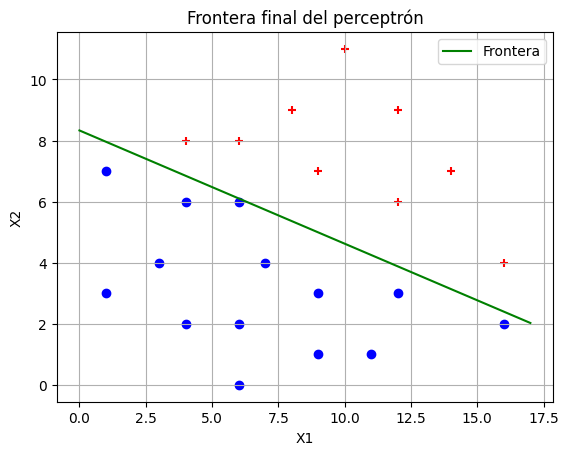

In [20]:

# Graficar la frontera final
perceptron_plot(X, y, w_final, "Frontera final del perceptrón")


**Pregunta guía: ¿Qué diferencias existen entre la frontera inicial y la frontera final?**

La frontera inicial se generó con pesos aleatorios y podía clasificar incorrectamente los puntos. En cambio, la frontera final utiliza los pesos ajustados durante el entrenamiento, por lo que permite separar mejor las dos clases.

## Fase 6. Clasificación de nuevos puntos

### Actividad 6.a — Predicción de nuevos puntos

Se evalúa el perceptrón entrenado utilizando tres puntos nuevos para observar a qué clase pertenece cada uno según los pesos finales del modelo.

In [21]:

# Nuevos puntos de prueba
X_test = [[5, 5], [10, 6], [6, 10]]

# Clasificar cada punto
print("Punto\t\tClase predicha")

for punto in X_test:
    prediccion = perceptron_compute(punto, w_final)
    print(punto, "\t", prediccion)


Punto		Clase predicha
[5, 5] 	 -1
[10, 6] 	 1
[6, 10] 	 1


**Pregunta guía: ¿Las predicciones de los nuevos puntos son coherentes con la frontera de decisión obtenida?**

Las predicciones son coherentes con la frontera de decisión, ya que el perceptrón asigna a cada punto una clase según el lado de la recta en el que se encuentra.

### Actividad 6.b — Visualización de los nuevos puntos

Se representan los datos originales junto con los nuevos puntos de prueba y la frontera de decisión final, para comprobar visualmente las clasificaciones realizadas por el perceptrón.

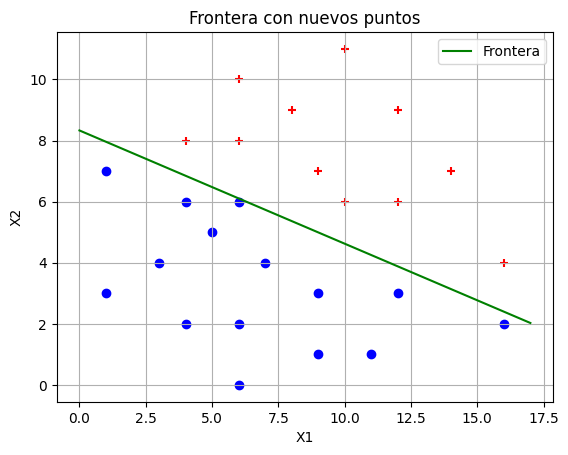

In [22]:

# Unir los datos originales con los nuevos puntos
X_nuevo = X + X_test

# Obtener las clases predichas
y_test = []

for punto in X_test:
    prediccion = perceptron_compute(punto, w_final)
    y_test.append(prediccion)

# Unir las clases originales con las predicciones
y_nuevo = y + y_test

# Graficar todos los puntos
perceptron_plot(X_nuevo, y_nuevo, w_final,
                "Frontera con nuevos puntos")


**Pregunta guía: ¿Existen puntos nuevos cuya clasificación resulte dudosa?**

Los puntos cercanos a la frontera de decisión pueden considerarse más dudosos, porque pequeños cambios en su posición podrían modificar la clase asignada. Sin embargo, el perceptrón los clasifica según el lado de la recta en el que se encuentran.

## Fase 7. Evolución de la frontera de decisión

### Actividad 7.a — Visualización de la evolución

Se grafican diferentes etapas del entrenamiento del perceptrón para observar cómo cambia la frontera de decisión a medida que se actualizan los pesos.

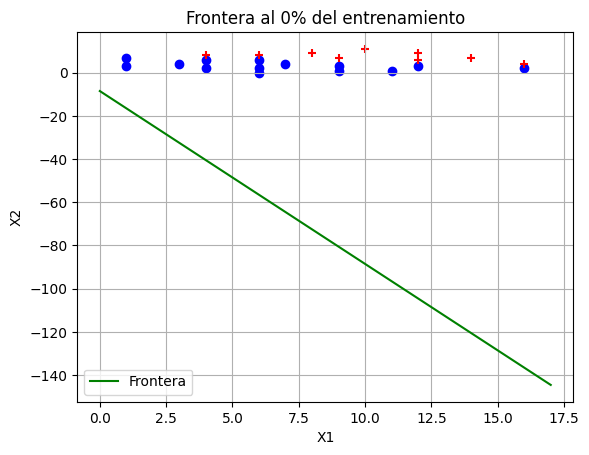

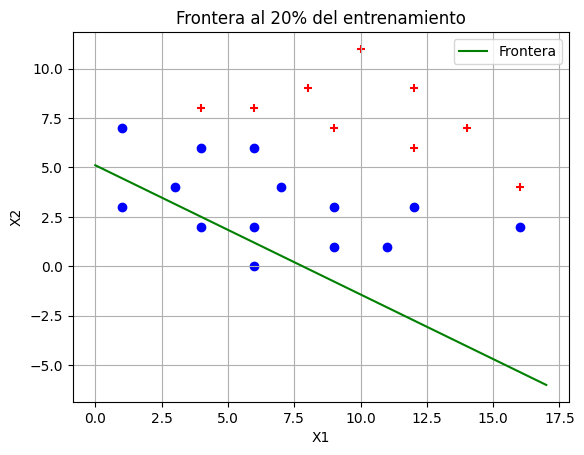

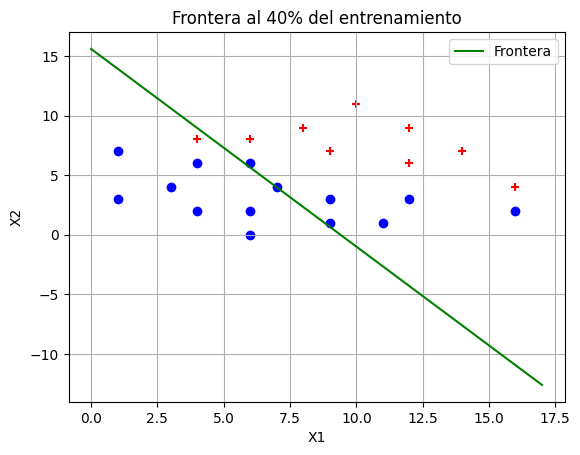

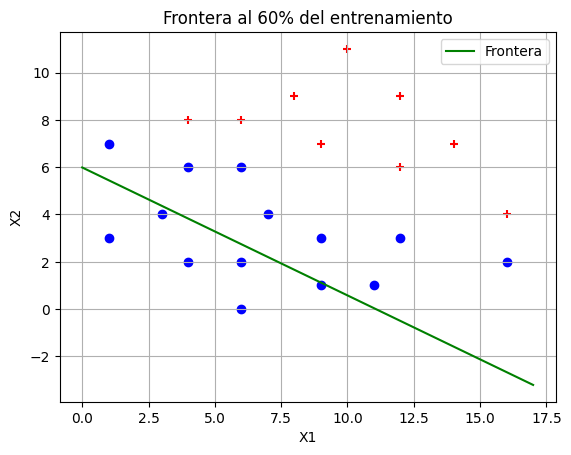

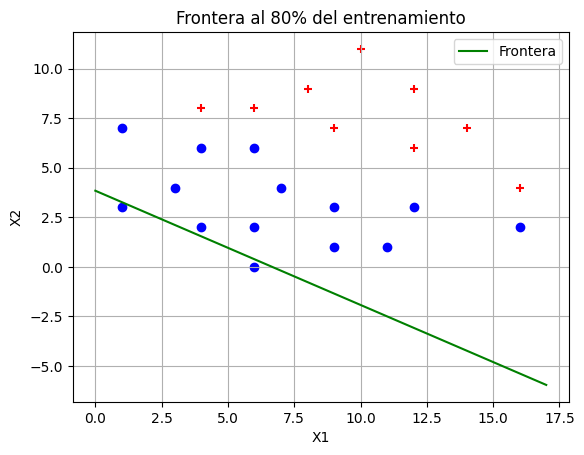

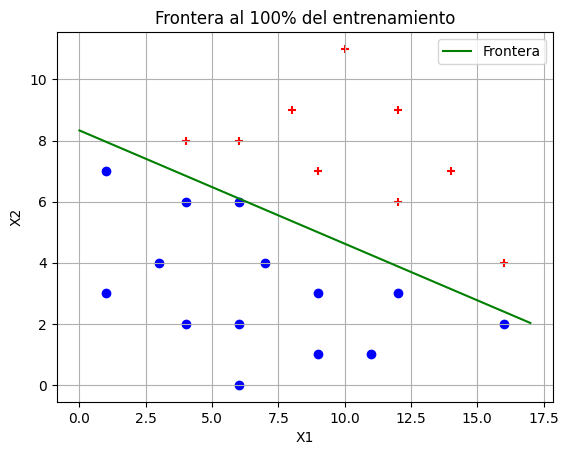

In [23]:

# Momentos del entrenamiento
porcentajes = [0, 20, 40, 60, 80, 100]

# Mostrar las fronteras de decisión
for porcentaje in porcentajes:
    if porcentaje == 0:
        pesos = w_initial
    else:
        posicion = int((len(W_values) - 1) * porcentaje / 100)
        pesos = W_values[posicion]

    perceptron_plot(
        X, y, pesos,
        "Frontera al " + str(porcentaje) + "% del entrenamiento"
    )


**Pregunta guía: ¿Cómo cambia la frontera de decisión durante el entrenamiento?**

La frontera de decisión cambia su posición e inclinación a medida que el perceptrón actualiza sus pesos para corregir los errores de clasificación.

**¿En qué momento se estabiliza la frontera?**

La frontera se estabiliza cuando el perceptrón deja de cometer errores y ya no necesita actualizar sus pesos.

### Actividad 7.b — Análisis de la pendiente y el sesgo

Se analiza cómo los pesos del perceptrón influyen en la pendiente y posición de la frontera de decisión, comparando los valores iniciales y finales del entrenamiento.

In [24]:

# Mostrar pesos iniciales y finales
print("Pesos iniciales:", [round(v, 4) for v in w_initial])
print("Pesos finales:", [round(v, 4) for v in w_final])

# Calcular las pendientes
if w_initial[2] != 0:
    pendiente_inicial = -w_initial[1] / w_initial[2]
    print("Pendiente inicial:", round(pendiente_inicial, 4))

if w_final[2] != 0:
    pendiente_final = -w_final[1] / w_final[2]
    print("Pendiente final:", round(pendiente_final, 4))

# Mostrar el sesgo
print("Sesgo inicial:", round(w_initial[0], 4))
print("Sesgo final:", round(w_final[0], 4))


Pesos iniciales: [-0.4883, -0.4598, -0.0574]
Pesos finales: [-124.4883, 5.5402, 14.9426]
Pendiente inicial: -8.0042
Pendiente final: -0.3708
Sesgo inicial: -0.4883
Sesgo final: -124.4883


**Pregunta guía: ¿Cómo influyen los pesos y el sesgo en la frontera de decisión?**

Los pesos w1 y w2 determinan la inclinación de la frontera de decisión, mientras que el sesgo w0 influye en su posición. Durante el entrenamiento, estos valores se ajustan para mejorar la clasificación de los puntos.

**¿Por qué cambia la pendiente durante el aprendizaje?**

Porque el perceptrón modifica sus pesos cuando comete errores, lo que puede cambiar la inclinación de la recta hasta conseguir una mejor separación de las clases.

## Fase 8. Análisis del error del perceptrón

### Actividad 8.a — Gráfica de la evolución del error

Se implementa una función para representar gráficamente la tasa de error del perceptrón en cada época del entrenamiento, con el objetivo de analizar su evolución y comprobar si el modelo converge.

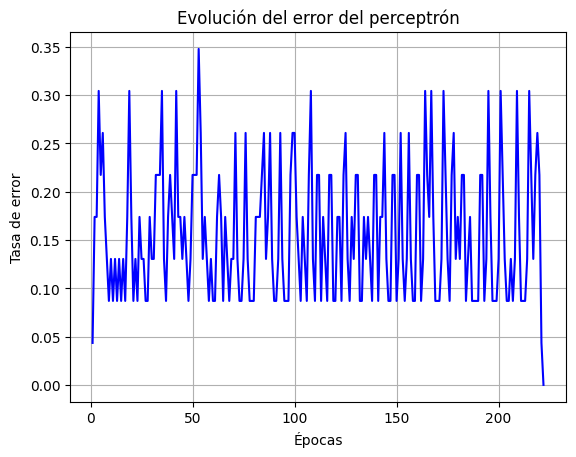

In [25]:

def plot_error(E_values, title):
    epocas = range(1, len(E_values) + 1)

    plt.plot(epocas, E_values, color="blue")

    plt.xlabel("Épocas")
    plt.ylabel("Tasa de error")
    plt.title(title)
    plt.grid()
    plt.show()

# Graficar el error del entrenamiento
plot_error(E_values, "Evolución del error del perceptrón")


**Pregunta guía: ¿El error disminuye de manera monótona durante el entrenamiento?**

No necesariamente. La tasa de error puede aumentar o disminuir entre épocas, porque las actualizaciones de los pesos pueden corregir algunas clasificaciones y modificar otras. Sin embargo, el objetivo del entrenamiento es alcanzar una tasa de error igual a cero.

### Actividad 8.b — Interpretación del error final

Se analiza la tasa de error final del perceptrón para determinar si logró clasificar correctamente los datos de entrenamiento y evaluar su capacidad de generalización.

In [26]:

# Mostrar el error final
error_final = E_values[-1]

print("Error final:", round(error_final, 4))

if error_final == 0:
    print("El perceptrón clasificó correctamente todos los datos de entrenamiento.")
else:
    print("El perceptrón todavía presenta errores de clasificación.")


Error final: 0.0
El perceptrón clasificó correctamente todos los datos de entrenamiento.


**Pregunta guía: ¿Qué significa que el error final sea igual a cero?**

Significa que el perceptrón logró clasificar correctamente todos los puntos utilizados durante el entrenamiento.

**¿Un error de entrenamiento igual a cero garantiza que el modelo clasificará correctamente nuevos datos?**

No. Aunque el perceptrón clasifique correctamente todos los datos de entrenamiento, puede cometer errores con puntos nuevos que no haya visto anteriormente.

**¿Por qué es importante evaluar la generalización del modelo?**

Porque permite comprobar si el perceptrón puede realizar buenas predicciones con datos diferentes a los utilizados durante el entrenamiento.

## Fase 9. Comparación de tasas de aprendizaje

### Actividad 9.a — Entrenamiento con diferentes tasas de aprendizaje

Se entrena el perceptrón con tasas de aprendizaje de 0.3, 0.5 y 0.8, utilizando los mismos pesos iniciales y un máximo de 1000 épocas para comparar los resultados.

In [27]:

# Tasas de aprendizaje
tasas = [0.3, 0.5, 0.8]

# Guardar los resultados
resultados = {}

# Entrenar con cada tasa
for tasa in tasas:
    w, epocas, updates, W, E = perceptron_learning(
        X, y, w_initial, tasa, 1000
    )

    resultados[tasa] = (w, epocas, updates, W, E)

    print("Tasa de aprendizaje:", tasa)
    print("Pesos finales:", [round(v, 4) for v in w])
    print("Épocas:", epocas)
    print("Actualizaciones:", updates)
    print("Error final:", round(E[-1], 4))
    print("------------------------------")


Tasa de aprendizaje: 0.3
Pesos finales: [-41.8883, 1.3402, 5.3426]
Épocas: 122
Actualizaciones: 389
Error final: 0.0
------------------------------
Tasa de aprendizaje: 0.5
Pesos finales: [-124.4883, 5.5402, 14.9426]
Épocas: 222
Actualizaciones: 800
Error final: 0.0
------------------------------
Tasa de aprendizaje: 0.8
Pesos finales: [-213.2883, 9.1402, 25.5426]
Épocas: 261
Actualizaciones: 891
Error final: 0.0
------------------------------


**Pregunta guía: ¿Por qué es importante utilizar los mismos pesos iniciales al comparar las tasas de aprendizaje?**

Porque permite realizar una comparación justa entre los entrenamientos. De esta manera, las diferencias en los resultados se deben principalmente a la tasa de aprendizaje y no a distintos pesos iniciales.

In [28]:

# Buscar la tasa que necesitó menos épocas
mejor_tasa = min(tasas, key=lambda tasa: resultados[tasa][1])

print("Tasa con menos épocas:", mejor_tasa)
print("Número de épocas:", resultados[mejor_tasa][1])


Tasa con menos épocas: 0.3
Número de épocas: 122


### Actividad 9.b — Visualización de la evolución para cada tasa

Se representa la evolución de la frontera de decisión y de la tasa de error para los entrenamientos realizados con tasas de aprendizaje de 0.3, 0.5 y 0.8.

Tasa de aprendizaje: 0.3


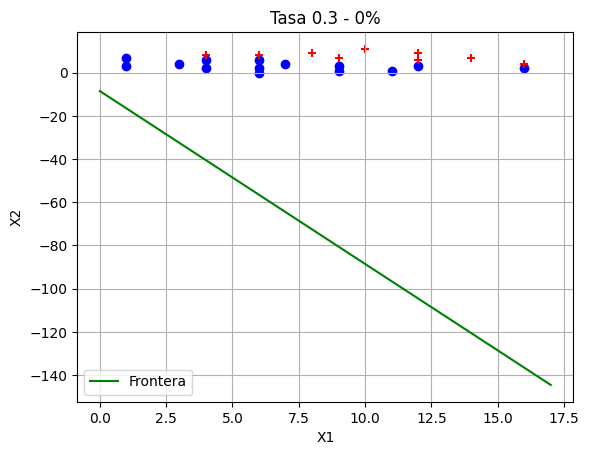

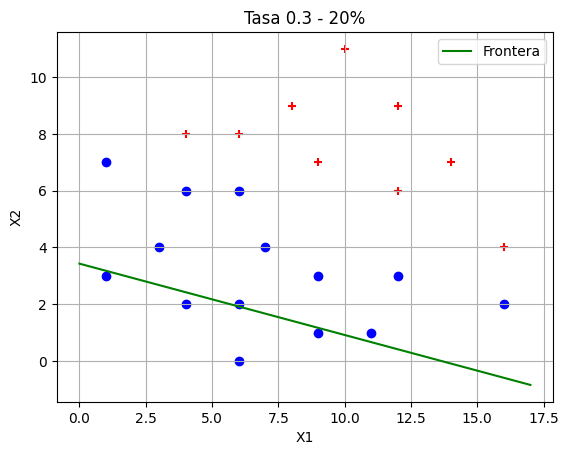

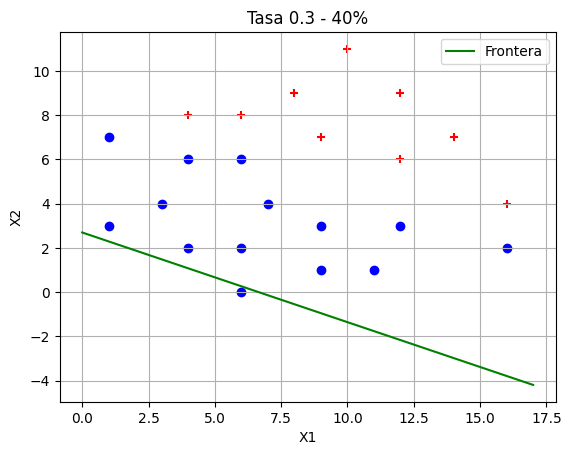

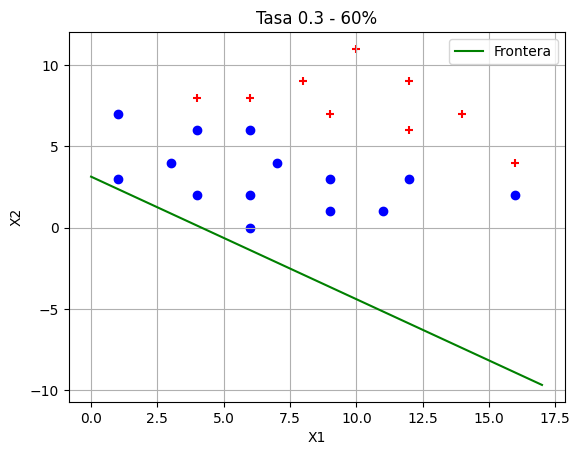

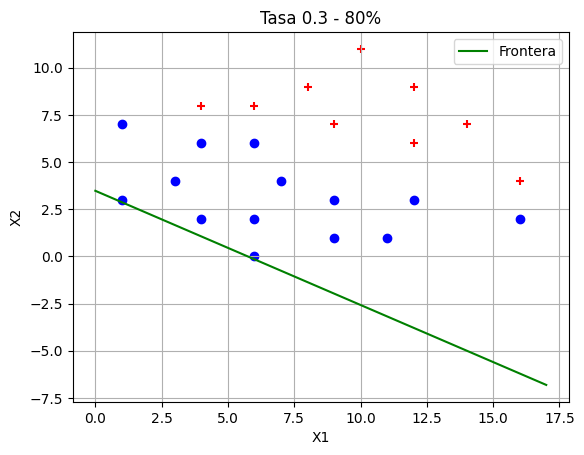

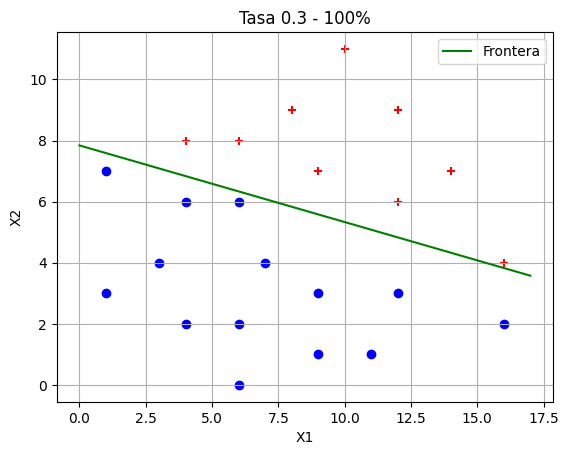

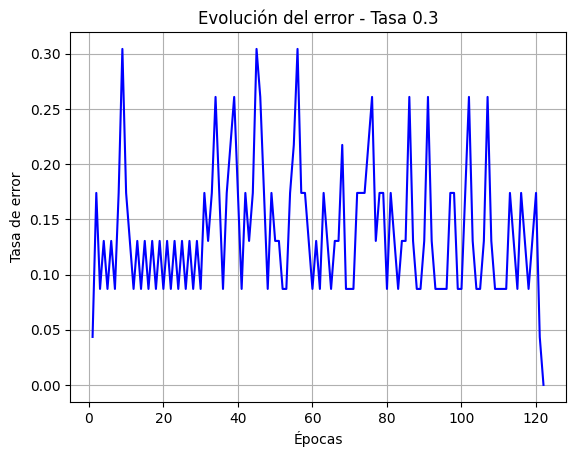

Tasa de aprendizaje: 0.5


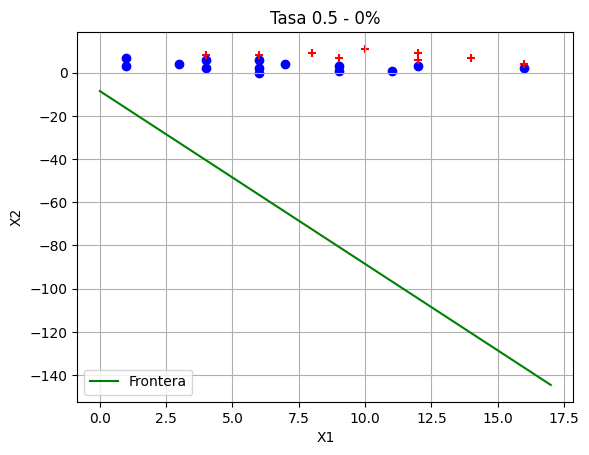

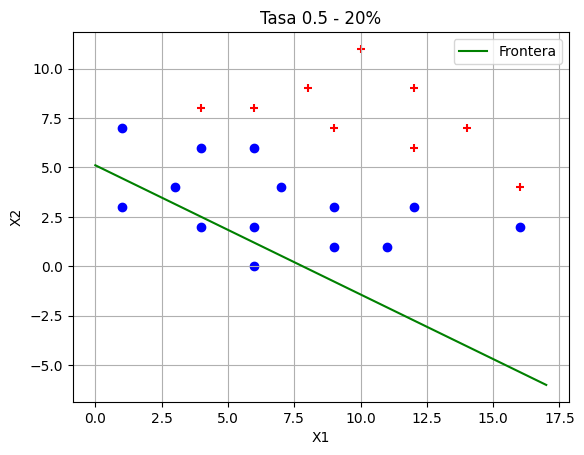

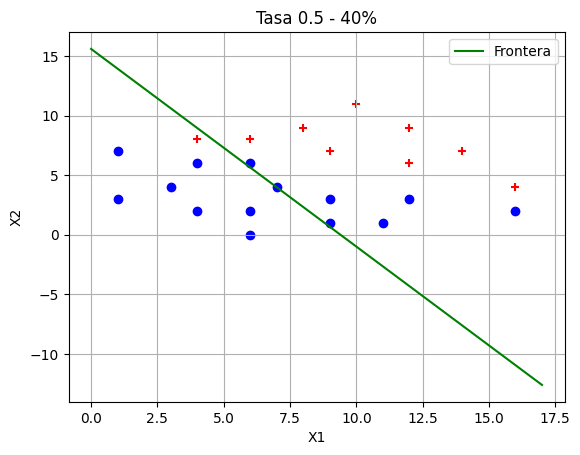

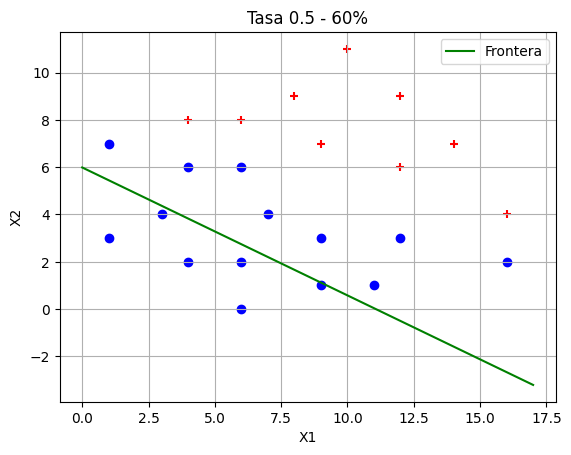

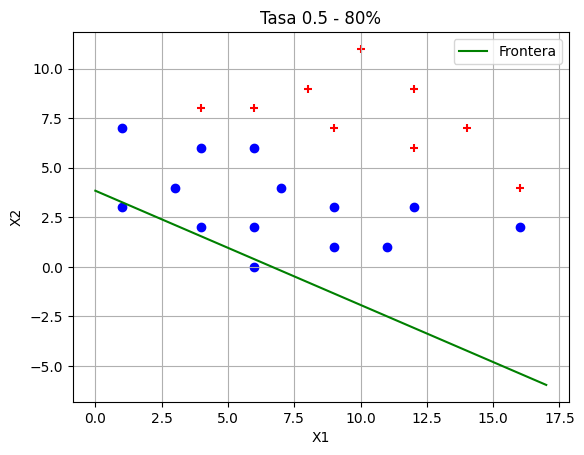

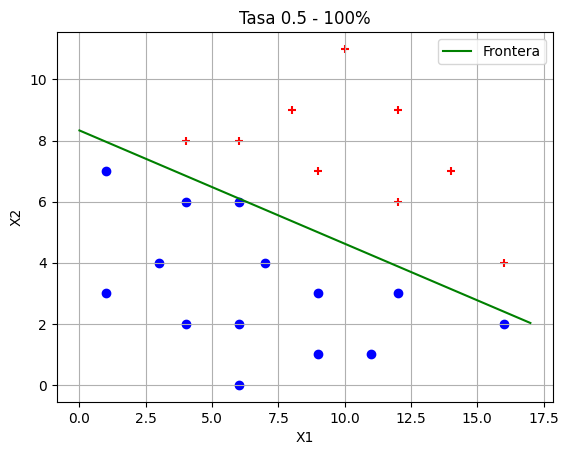

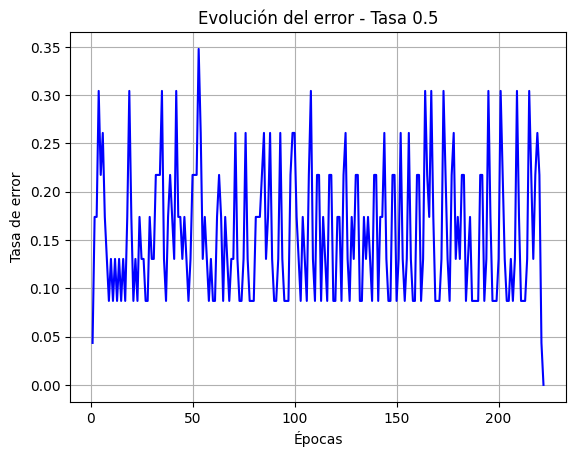

Tasa de aprendizaje: 0.8


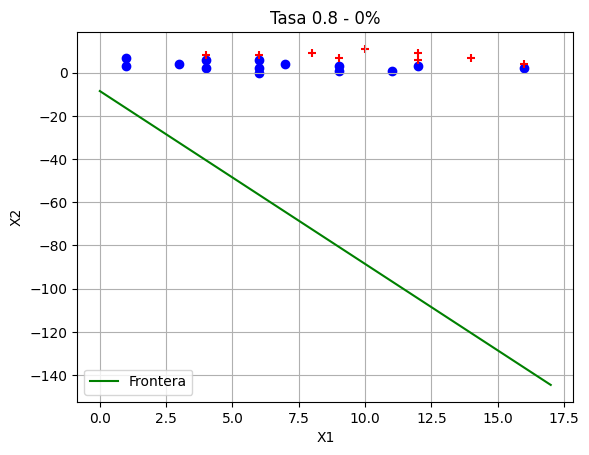

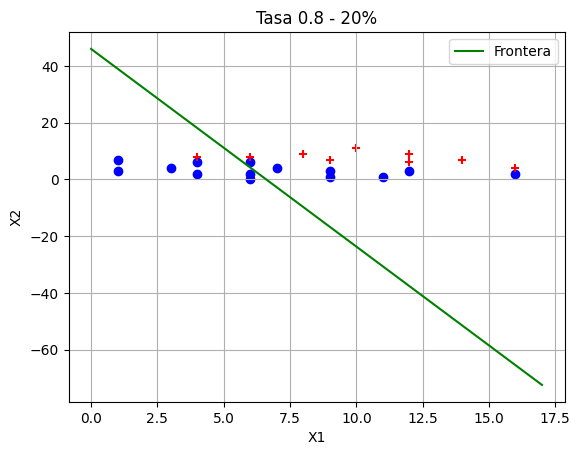

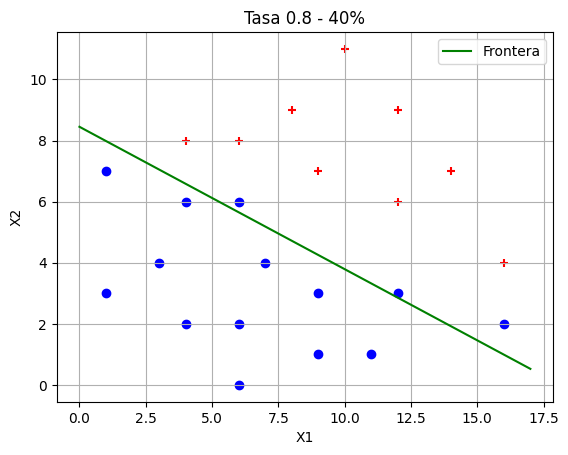

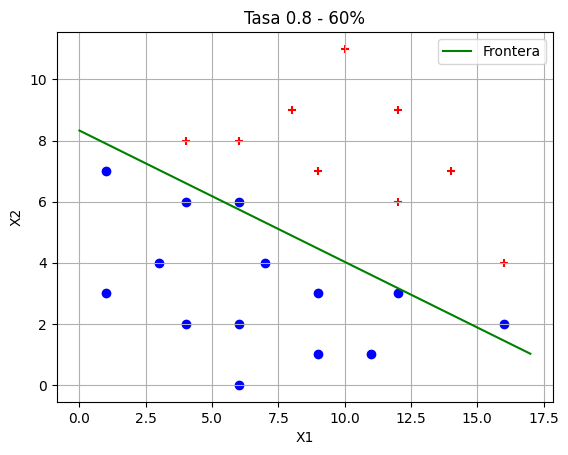

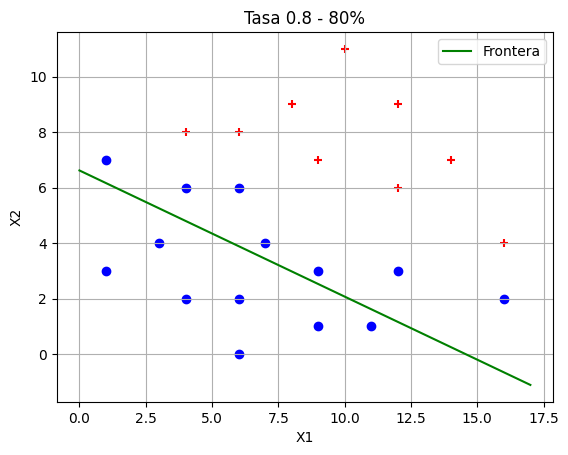

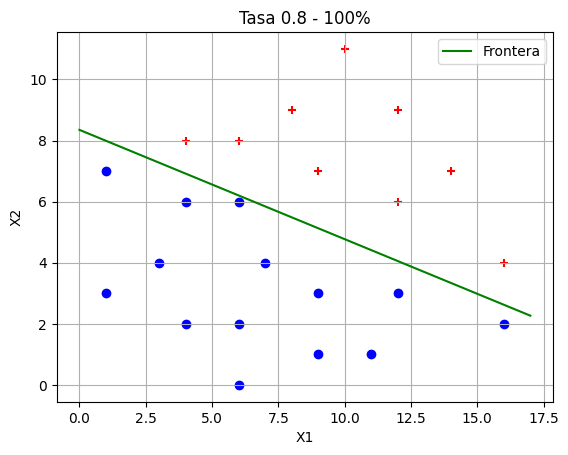

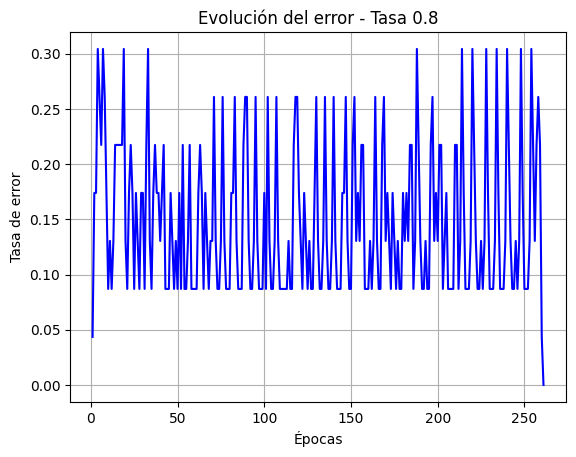

In [29]:

# Mostrar la evolución para cada tasa
for tasa in tasas:
    w, epocas, updates, W, E = resultados[tasa]

    print("Tasa de aprendizaje:", tasa)

    # Mostrar seis momentos del entrenamiento
    for porcentaje in [0, 20, 40, 60, 80, 100]:
        if porcentaje == 0:
            pesos = w_initial
        else:
            posicion = int((len(W) - 1) * porcentaje / 100)
            pesos = W[posicion]

        perceptron_plot(
            X, y, pesos,
            "Tasa " + str(tasa) + " - " + str(porcentaje) + "%"
        )

    # Graficar el error
    plot_error(E, "Evolución del error - Tasa " + str(tasa))


In [30]:

for tasa in tasas:
    print("Tasa:", tasa,
          "| Épocas:", resultados[tasa][1],
          "| Error final:", round(resultados[tasa][4][-1], 4))


Tasa: 0.3 | Épocas: 122 | Error final: 0.0
Tasa: 0.5 | Épocas: 222 | Error final: 0.0
Tasa: 0.8 | Épocas: 261 | Error final: 0.0


**Pregunta guía: ¿Qué tasa de aprendizaje logró converger en menos épocas?**

La tasa que convergió en menos épocas se identifica comparando los resultados de los tres entrenamientos, considerando únicamente aquellos que alcanzaron un error final igual a cero.

**¿La tasa que converge más rápido es necesariamente la mejor?**

No necesariamente. Una tasa de aprendizaje puede necesitar menos épocas, pero también es importante considerar la estabilidad del entrenamiento, las actualizaciones realizadas y la capacidad de clasificar nuevos datos.

### Actividad 9.c — Tabla comparativa de resultados

Se elabora una tabla comparativa de los entrenamientos realizados con diferentes tasas de aprendizaje, considerando el número de épocas, las actualizaciones, el error final y los pesos obtenidos.

In [31]:

import pandas as pd

# Crear la tabla comparativa
tabla = []

for tasa in tasas:
    w, epocas, updates, W, E = resultados[tasa]

    tabla.append({
        "Tasa": tasa,
        "Épocas": epocas,
        "Actualizaciones": updates,
        "Error final": round(E[-1], 4),
        "Pesos finales": [round(v, 4) for v in w]
    })

# Mostrar la tabla
df = pd.DataFrame(tabla)
display(df)


,Tasa,Épocas,Actualizaciones,Error final,Pesos finales
0,0.3,122,389,0.0,"[-41.8883, 1.3402, 5.3426]"
1,0.5,222,800,0.0,"[-124.4883, 5.5402, 14.9426]"
2,0.8,261,891,0.0,"[-213.2883, 9.1402, 25.5426]"


**Pregunta guía: ¿Por qué diferentes tasas de aprendizaje pueden producir distintos pesos finales, aunque clasifiquen correctamente los mismos puntos?**

Porque cada tasa de aprendizaje modifica los pesos con una magnitud diferente durante el entrenamiento. Por esta razón, el perceptrón puede encontrar distintas fronteras de decisión que separan correctamente las mismas dos clases.

In [32]:

# Mostrar la tasa que convergió en menos épocas
convergentes = df[df["Error final"] == 0]

if len(convergentes) > 0:
    mejor = convergentes.loc[convergentes["Épocas"].idxmin()]
    print("Tasa con menos épocas:", mejor["Tasa"])
    print("Épocas utilizadas:", mejor["Épocas"])
else:
    print("Ninguna tasa alcanzó error cero.")


Tasa con menos épocas: 0.3
Épocas utilizadas: 122


## Conclusiones

1. Se implementó correctamente el algoritmo del perceptrón, permitiendo clasificar datos en dos clases mediante el ajuste de pesos y el sesgo.

2. Durante el entrenamiento se observó cómo la frontera de decisión cambiaba su posición e inclinación hasta conseguir una separación correcta de los datos.

3. Las tres tasas de aprendizaje evaluadas (0.3, 0.5 y 0.8) alcanzaron un error final de 0.0, demostrando que el perceptrón logró clasificar correctamente los datos de entrenamiento.

4. La tasa de aprendizaje **0.3 obtuvo los mejores resultados en este experimento**, ya que necesitó solamente 122 épocas y 389 actualizaciones, mientras que las tasas 0.5 y 0.8 requirieron más iteraciones.

5. Se comprobó que una tasa de aprendizaje mayor no garantiza una convergencia más rápida. Además, alcanzar un error de entrenamiento igual a cero no asegura que el modelo clasifique correctamente todos los datos nuevos.